# Clustered DML: a customer offer across local markets

Estimate the effect of a targeted offer on a continuous customer outcome using
binary-treatment double machine learning (`IRM`). Customers in the same market
share assignment and outcome shocks, so independent sampling units are **markets**.

This self-contained example generates all data locally, fits cluster-disjoint
cross-fitting folds, estimates ATE and ATTE, and inspects cluster-aware refutation
diagnostics and sensitivity intervals. Run the cells in order with a Python
kernel using the local Causalis installation (`.venv`). No data download is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, t
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from causalis.data_contracts import CausalData
from causalis.dgp import generate_obs_clustered
from causalis.scenarios.unconfoundedness import IRM
from causalis.scenarios.unconfoundedness.refutation import (
    run_overlap_diagnostics,
    run_unconfoundedness_diagnostics,
    run_score_diagnostics,
    plot_m_overlap,
    plot_propensity_reliability,
    plot_feature_importance,
    love_plot,
    plot_influence_instability,
    plot_residual_diagnostics,
    sensitivity_analysis,
    sensitivity_benchmark_group,
)

SEED = 19
ALPHA = 0.05
pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)

## 1. Generate dependent observations with known effects

Markets contain 20, 40, 60 or 80 customers. Offer assignment depends on observed
pre-treatment features, including market income. Independent latent shocks
create within-market dependence in treatment and in outcomes. There are no
spillovers, and the generator satisfies unconfoundedness conditional on the
observed features; neither fact follows merely from declaring a cluster column.

`treatment_correlation=0.7` is the correlation of the **latent assignment
normals**, not the ICC of binary treatment. With outcome shock standard
deviations 2 and 1, conditional outcome residual ICC is $4/(4+1)=0.8$.

In [2]:
cluster_sizes = np.tile([20, 40, 60, 80], 30)
population_ate = 1.5

frame = generate_obs_clustered(
    n=int(cluster_sizes.sum()),
    n_clusters=len(cluster_sizes),
    cluster_sizes=cluster_sizes,
    theta=population_ate,
    heterogeneity=0.5,
    sigma_y=1.0,
    sigma_cluster=2.0,
    treatment_correlation=0.7,
    seed=SEED,
    include_oracle=True,
    return_causal_data=False,
)
display(frame[["cluster", "d", "y", "age_years", "premium_user", "market_median_income"]].head())

,cluster,d,y,age_years,premium_user,market_median_income
0,0,1.0,16.744103,46.0,1.0,89456.534334
1,0,1.0,15.595005,52.0,1.0,89456.534334
2,0,1.0,11.426123,50.0,0.0,89456.534334
3,0,1.0,14.043025,42.0,0.0,89456.534334
4,0,1.0,15.140833,24.0,0.0,89456.534334


`cluster` supplies the sampling/dependence structure. Keep the observed
`market_median_income` in the adjustment set because it affects treatment and
outcome. The cluster identifier itself is not a nuisance-model feature.

The extra `m`, `m_obs`, `g0`, `g1` and `cate` columns are simulation oracles.
They stay outside the analysis contract and are never passed to the learners.
In particular, `m` is the marginal propensity given observed X; `m_obs` also
conditions on the unobserved assignment shock and is not an observed feature.

In [3]:
confounders = [
    "age_years", "tenure_months", "avg_sessions_week", "spend_last_month",
    "income_monthly", "premium_user", "mobile_user", "market_median_income",
]
data = CausalData.from_df(
    frame, treatment="d", outcome="y", confounders=confounders, cluster="cluster",
)

assert not set(["cluster", "m", "m_obs", "g0", "g1", "cate"]) & set(data.confounders)
np.testing.assert_allclose(frame.g1 - frame.g0, frame.cate)

market_summary = frame.groupby("cluster", sort=False).agg(
    customers=("d", "size"), treated=("d", "sum"), outcome_mean=("y", "mean"),
)
market_summary["treated_share"] = market_summary.treated / market_summary.customers
display(pd.Series({
    "customers": len(frame),
    "independent_markets": len(market_summary),
    "smallest_market": market_summary.customers.min(),
    "largest_market": market_summary.customers.max(),
    "treated_only_markets": int((market_summary.treated_share == 1).sum()),
    "control_only_markets": int((market_summary.treated_share == 0).sum()),
    "raw_treated_minus_control": frame.loc[frame.d == 1, "y"].mean() - frame.loc[frame.d == 0, "y"].mean(),
}, name="Sample overview").to_frame())

,Sample overview
customers,6000.000000
independent_markets,120.000000
smallest_market,20.000000
largest_market,80.000000
treated_only_markets,6.000000
control_only_markets,13.000000
raw_treated_minus_control,2.667572


With unequal market sizes, the target still weights **customers**, not market
means equally. `theta=1.5` is the population ATE. Realized sample oracle ATE and
ATTE can differ from it and from each other because the effect is heterogeneous.
These sample quantities are useful simulation benchmarks; a single confidence
interval covering one benchmark is not a coverage study.

In [4]:
sample_oracle = {
    "ATE": float(frame.cate.mean()),
    "ATTE": float(frame.loc[frame.d == 1, "cate"].mean()),
}
display(pd.Series({
    "population ATE": population_ate,
    "realized sample ATE": sample_oracle["ATE"],
    "realized sample ATTE": sample_oracle["ATTE"],
}, name="Known simulation effects").to_frame())

,Known simulation effects
population ATE,1.500000
realized sample ATE,1.453967
realized sample ATTE,1.552634


## 2. Fit DML with whole-market cross-fitting

Conservative random forests estimate the outcome and propensity nuisances.
Each held-out market is entirely excluded from nuisance training for its fold.
Ordinary row-wise cross-validation would leak shared market shocks.
For tuned models, inner validation must also respect the same grouping.

We use canonical unnormalized IPW (`normalize_ipw=False`) and clipping at 0.01.
Clipping retains the sample; dropping low-overlap rows would change the target
population. A market need not contain both treatment arms; the training splits
still need support for both nuisance outcome models.

In [5]:
model = IRM(
    data=data,
    ml_g=RandomForestRegressor(
        n_estimators=80, max_depth=6, min_samples_leaf=20,
        n_jobs=1, random_state=SEED,
    ),
    ml_m=RandomForestClassifier(
        n_estimators=80, max_depth=6, min_samples_leaf=20,
        n_jobs=1, random_state=SEED,
    ),
    n_folds=3,
    random_state=SEED,
    normalize_ipw=False,
    overlap_policy="clip",
    overlap_threshold=0.01,
    store_diagnostics=True,
).fit()

fold_check = pd.DataFrame({"cluster": data.cluster.to_numpy(), "fold": model.folds_})
assert fold_check.groupby("cluster")["fold"].nunique().eq(1).all()
display(fold_check.groupby("fold").agg(
    customers=("cluster", "size"), independent_markets=("cluster", "nunique"),
))

,customers,independent_markets
fold,,
0,1960,40
1,2060,40
2,1980,40


## 3. Estimate ATE and inspect the sampling uncertainty

The effect estimate uses the usual observation-weighted orthogonal score.
Declaring clusters changes the cross-fitting design and inference, while
preserving that target. IRM reports one-way CR1 covariance and Student's t
intervals with `G - 1` degrees of freedom.

In [6]:
ate = model.estimate(score="ATE", alpha=ALPHA)
display(ate.summary())

,value
field,
outcome,y
estimand,ATE
model,IRM
value,"1.5912 (ci_abs: 1.0193, 2.1631)"
value_relative,"18.4796 (ci_rel: 11.0066, 25.9527)"
alpha,0.0500
p_value,0.0000
is_significant,True
n_treated,2476


### Same fitted scores, different covariance assumptions

Let $\psi_i$ be a saved row influence and center it as
$u_i=\psi_i-\bar\psi$. For cluster totals $U_g=\sum_{i\in g}u_i$,

$$
\widehat{\mathrm{Var}}_{cluster}(\hat\theta)
=\frac{G}{G-1}\frac{\sum_g U_g^2}{n^2}.
$$

The IID comparison uses $s^2(\psi)/n$ and a normal reference. Both calculations
below use **the exact same point estimate, nuisance predictions and folds**.
Refitting an IID model would also change the splits and obscure this comparison.
This DGP makes ignored dependence visible; cluster SEs need not exceed IID SEs
in every dataset.

In [7]:
psi = np.asarray(ate.diagnostic_data.psi)
codes = ate.diagnostic_data.cluster_codes
n = len(psi)
cluster_totals = pd.Series(psi - psi.mean()).groupby(codes, sort=False).sum()
G = len(cluster_totals)

iid_se = float(np.std(psi, ddof=1) / np.sqrt(n))
cr1_variance = G / (G - 1) * float(cluster_totals @ cluster_totals) / n**2
cluster_se = float(np.sqrt(cr1_variance))
np.testing.assert_allclose(cluster_se, ate.model_options["std_error"], rtol=1e-12)
np.testing.assert_allclose(cluster_totals.sum(), 0.0, atol=1e-8)

uncertainty = pd.DataFrame([
    {"assumption": "IID rows (illustration only)", "effect": ate.value,
     "SE": iid_se, "critical_value": norm.ppf(1 - ALPHA / 2)},
    {"assumption": "Independent markets (CR1)", "effect": ate.value,
     "SE": cluster_se, "critical_value": t.ppf(1 - ALPHA / 2, df=G - 1)},
]).set_index("assumption")
uncertainty["CI lower"] = uncertainty.effect - uncertainty.critical_value * uncertainty.SE
uncertainty["CI upper"] = uncertainty.effect + uncertainty.critical_value * uncertainty.SE
display(uncertainty)
print(f"Cluster / IID standard-error ratio: {cluster_se / iid_se:.2f}")

,effect,SE,critical_value,CI lower,CI upper
assumption,,,,,
IID rows (illustration only),1.591202,0.067333,1.959964,1.459231,1.723172
Independent markets (CR1),1.591202,0.288827,1.980100,1.019296,2.163107


Cluster / IID standard-error ratio: 4.29


## 4. Refutation diagnostics

Overlap, calibration and standardized mean differences remain descriptive
summaries over customers. Cluster counts and concentration of cluster weight
mass reveal how widely support is distributed. Cluster weight concentration is
not a general ICC-adjusted effective sample size.

Traffic-light flags are screening heuristics. This example can produce yellow
or red nuisance-direction flags even though the generator's identification
assumptions are known: finite-sample learner performance still needs inspection.
Passing a diagnostic would not establish unconfoundedness or absence of spillovers.

In [8]:
overlap = run_overlap_diagnostics(data, ate)
balance = run_unconfoundedness_diagnostics(data, ate)
score = run_score_diagnostics(data, ate)

np.testing.assert_allclose(
    score["influence_diagnostics"]["se_plugin"], cluster_se, rtol=1e-12,
)
display(pd.DataFrame([
    {"diagnostic": name,
     "RED flags": sum(flag == "RED" for flag in report["flags"].values()),
     "YELLOW flags": sum(flag == "YELLOW" for flag in report["flags"].values()),
     "retained_clusters": report["meta"]["n_clusters"]}
    for name, report in [("Overlap", overlap), ("Balance", balance), ("Score", score)]
]).set_index("diagnostic"))
display(pd.Series(overlap["cluster_support"], name="Cluster support").to_frame())
display(pd.Series(overlap["cluster_weight_concentration"], name="Weight-mass concentration").to_frame())

,RED flags,YELLOW flags,retained_clusters
diagnostic,,,
Overlap,1,0,120
Balance,0,0,120
Score,1,1,120


,Cluster support
n_clusters,120
n_treated_clusters,107
n_control_clusters,114
n_mixed_clusters,101
n_treated_only_clusters,6
n_control_only_clusters,13


,Weight-mass concentration
w1,54.966242
w0,62.339476
att_w1,59.223463
att_w0,39.246306


,metric,value,flag
0,edge_0.01_below,0.000000,GREEN
1,edge_0.01_above,0.000000,GREEN
2,edge_0.02_below,0.000000,GREEN
3,edge_0.02_above,0.000000,GREEN
4,KS,0.292250,GREEN
5,AUC,0.689388,GREEN
6,support_rate,1.000000,GREEN
7,ESS_treated_ratio,0.827433,GREEN
8,ESS_control_ratio,0.836795,GREEN
9,tails_w1_q99/med,3.137146,GREEN


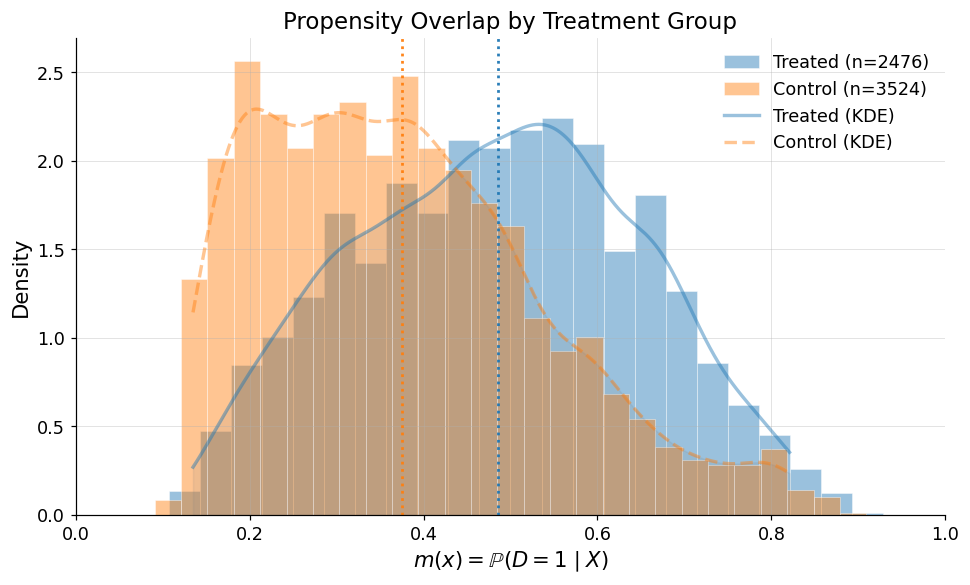

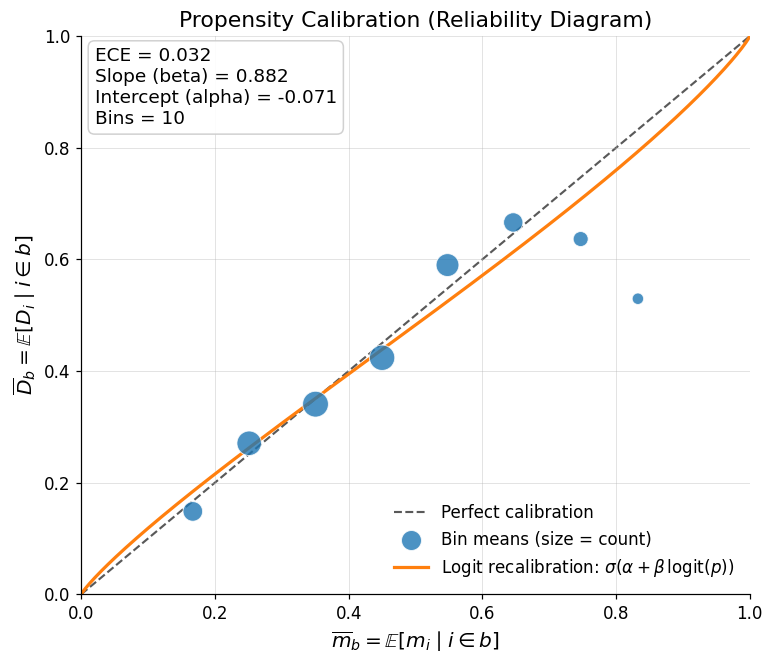

In [9]:
display(overlap["summary"])
display(plot_m_overlap(ate, dpi=110))
display(plot_propensity_reliability(ate, data=data, dpi=110))

,metric,value,flag
0,balance_max_smd,0.087111,GREEN
1,balance_frac_violations,0.000000,GREEN


,SMD_unweighted,SMD_weighted
age_years,0.121070,0.041154
tenure_months,0.155430,0.065039
avg_sessions_week,0.259616,0.074986
spend_last_month,0.354328,0.054079
income_monthly,0.401061,0.018882
premium_user,0.330885,0.087111
mobile_user,0.034111,0.043070
market_median_income,0.551873,0.013535


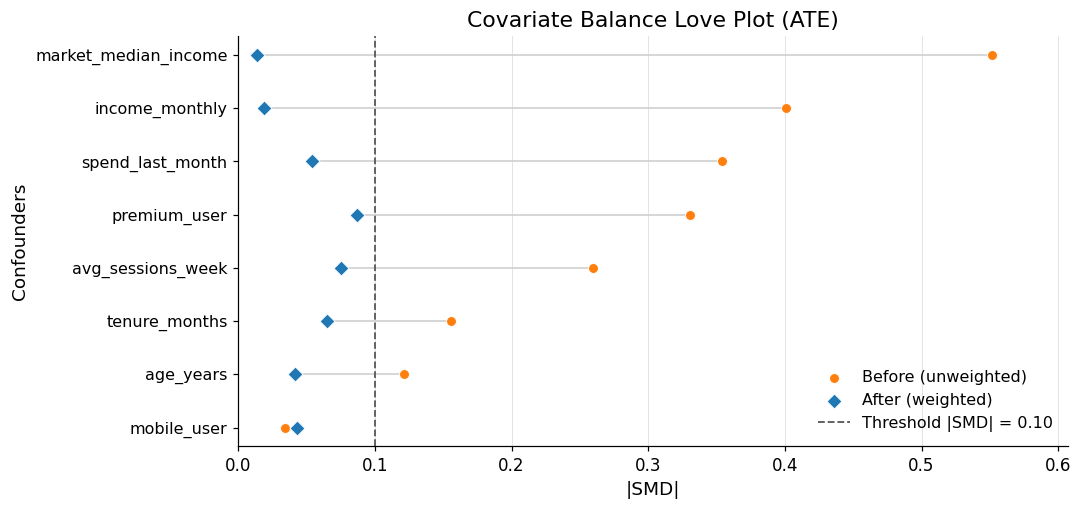

In [10]:
display(balance["summary"])
display(pd.concat([
    balance["balance"]["smd_unweighted"], balance["balance"]["smd"],
], axis=1))
display(love_plot(data, ate, dpi=110))

Score-direction SEs use grouped influence totals. Influence summaries rank
markets by $|\sum_{i\in g}\psi_i|$ by default; the contribution column divides
by the customer count $n$, and variance shares use centered influences.
These are influence diagnostics, not exact leave-market-out refits.

The old pooled OOS t/p-values are deliberately unavailable: leave-one-fold
estimates overlap in training data, and equal-size ATE folds cancel when pooled.
The fold table remains a descriptive stability check.

In [11]:
display(score["summary"])
display(score["orthogonality_derivatives"])
display(score["influence_diagnostics"]["top_influential"].head(6))
print("Pooled OOS inference available:", score["oos_moment_test"]["available"])
print(score["oos_moment_test"]["reason"])
display(score["oos_moment_test"]["fold_table"])

,metric,value,flag
0,psi_p99_over_med,7.235834,GREEN
1,psi_kurtosis,5.014592,GREEN
2,max_|t|_g1,1.892612,GREEN
3,max_|t|_g0,2.780075,YELLOW
4,max_|t|_m,5.284301,RED
5,oos_max_abs_t,NaN,NA


,basis,d_g1,se_g1,t_g1,d_g0,se_g0,t_g0,d_m,se_m,t_m
0,0,0.012972,0.091595,0.141623,0.044596,0.079025,0.564326,-0.404911,1.195790,-0.338614
1,1,-0.026605,0.020433,-1.302037,-0.014955,0.013880,-1.077455,-0.818743,0.261515,-3.130772
2,2,-0.028100,0.017166,-1.636911,-0.037456,0.013473,-2.780075,-1.205980,0.228219,-5.284301
3,3,-0.033072,0.019143,-1.727607,-0.042336,0.018560,-2.280993,-1.213198,0.329479,-3.682167
4,4,-0.034098,0.022634,-1.506507,-0.019627,0.027764,-0.706942,-1.578715,0.607402,-2.599126
5,5,-0.020197,0.047058,-0.429193,0.041894,0.082095,0.510310,-2.040117,1.343717,-1.518263
6,6,-0.042654,0.022537,-1.892612,-0.045751,0.018470,-2.477023,-1.448617,0.330251,-4.386417
7,7,-0.027895,0.019630,-1.421028,-0.015307,0.011394,-1.343408,-0.654700,0.205897,-3.179747
8,8,-0.040028,0.086727,-0.461539,0.056892,0.118018,0.482066,-1.324819,1.708901,-0.775246


,cluster,cluster_code,psi,n,m,treated_share,contribution,variance_share
0,14,14,-532.716442,60,0.771143,0.266667,-0.088786,0.095290
1,115,115,-487.237536,80,0.372559,0.000000,-0.081206,0.079715
2,26,26,-469.812277,60,0.410372,0.900000,-0.078302,0.074115
3,103,103,440.871399,80,0.365253,0.150000,0.073479,0.065265
4,43,43,-414.888594,80,0.396332,0.725000,-0.069148,0.057799
5,5,5,401.130464,40,0.292459,1.000000,0.066855,0.054029


Pooled OOS inference available: False
Pooled leave-one-fold moments can cancel algebraically and share training data; fold results are descriptive only.


,fold,n,theta_minus_k,psi_mean,psi_var
0,0,1960,1.503072,0.269784,26.265368
1,1,2060,1.783908,-0.561280,29.401743
2,2,1980,1.490898,0.303949,25.654099


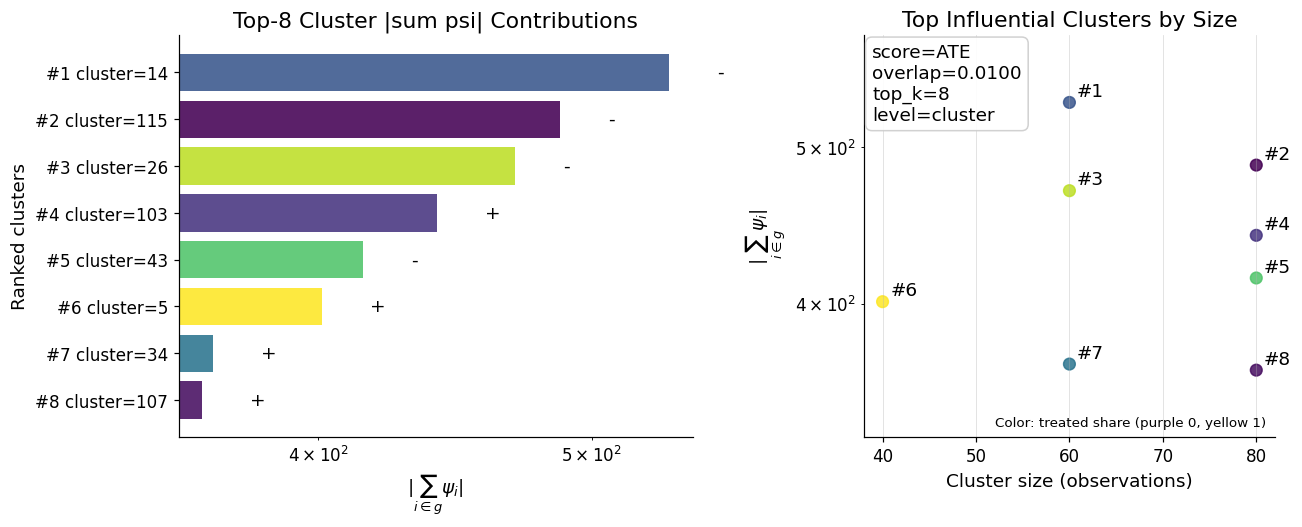

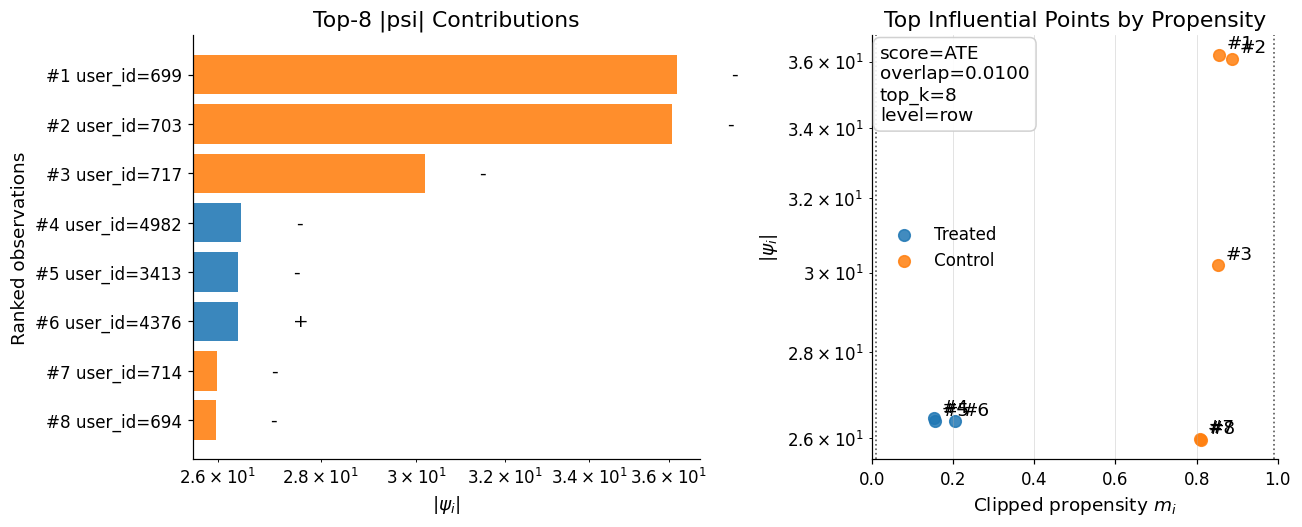

In [12]:
cluster_figure = plot_influence_instability(ate, data=data, top_k=8, dpi=110)
cluster_figure.axes[1].margins(y=0.25)  # Leave space for the treated-share color key.
display(cluster_figure)
# Explicitly request customers when a row-level drill-down is useful.
display(plot_influence_instability(ate, data=data, influence_level="row", top_k=8, dpi=110))

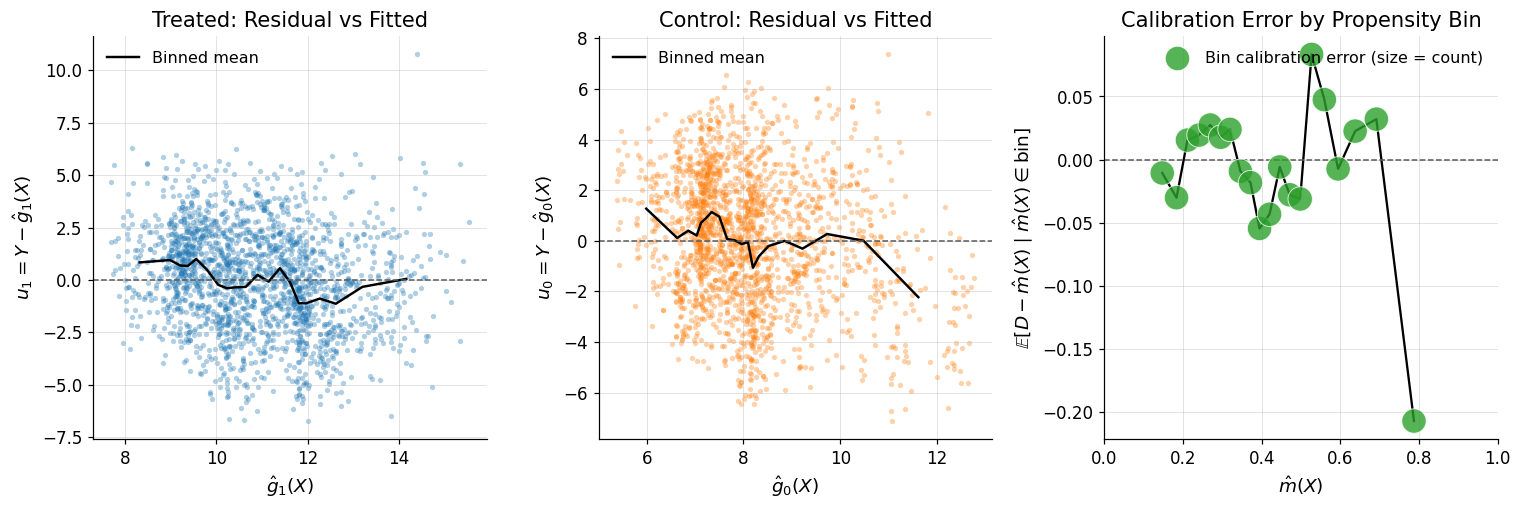

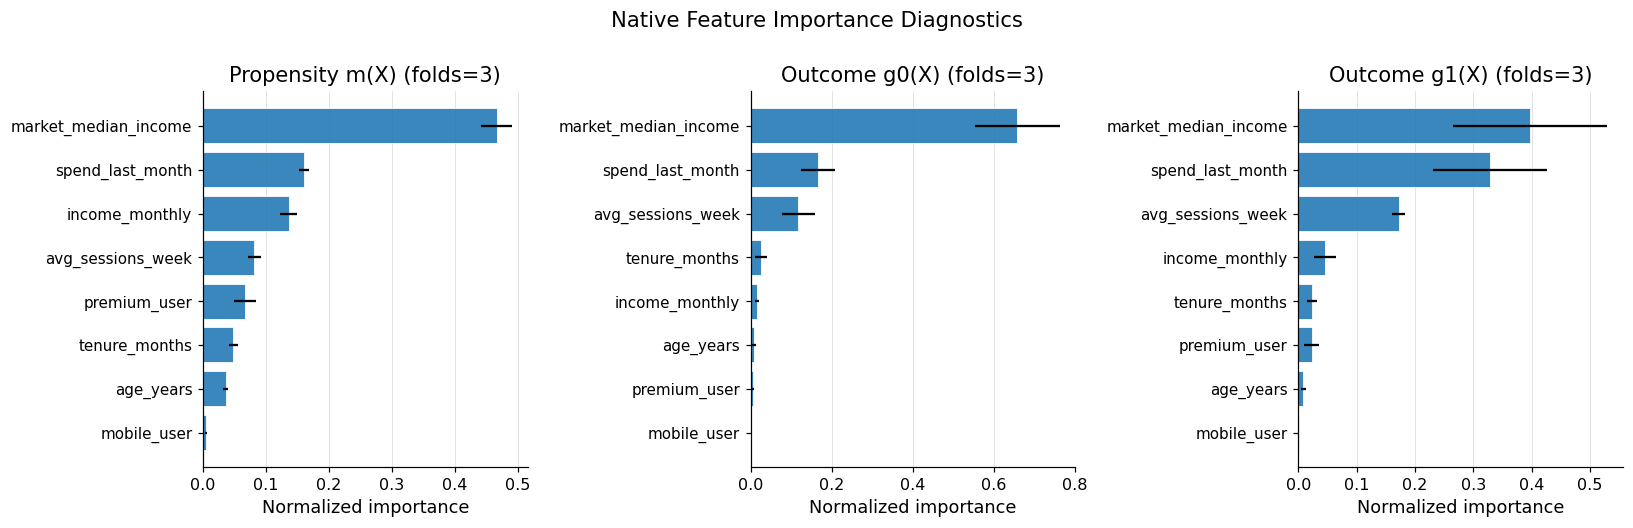

In [13]:
# Only scatter points are sampled; binned summaries always use all observations.
display(plot_residual_diagnostics(ate, data=data, max_scatter_points=2_000, random_state=SEED, dpi=110))
display(plot_feature_importance(ate, top_k=8, dpi=110))

## 5. Sensitivity to hypothetical omitted confounding

Clustering adjusts sampling uncertainty; it does not remove omitted-variable
bias. Here the DGP has no omitted common cause, but we can still ask how much
hypothetical confounding would change the inference.

`r2_y` is the partial outcome R-squared, `r2_d` is the relative Riesz variation
gain on its R-squared scale, and `rho=1` selects maximal adversity. This
sensitivity `rho` is unrelated to the DGP's latent `treatment_correlation`. The chosen
strengths are illustrative, not universal thresholds. Confidence limits use
joint cluster covariance for the effect and bias influences and the same
$t_{G-1}$ reference as IRM. At zero confounding they must recover the original CI.

In [14]:
zero = sensitivity_analysis(ate, r2_y=0.0, r2_d=0.0, rho=1.0, alpha=ALPHA)
np.testing.assert_allclose(
    zero["bias_aware_ci"], [ate.ci_lower_absolute, ate.ci_upper_absolute], rtol=1e-12,
)
assert zero["inference_df"] == G - 1

scenarios = []
for strength in [0.0, 0.01, 0.03, 0.05]:
    result = sensitivity_analysis(
        ate, r2_y=strength, r2_d=strength, rho=1.0, alpha=ALPHA,
    )
    scenarios.append({
        "r2_y = r2_d": strength,
        "effect bound lower": result["theta_bounds_cofounding"][0],
        "effect bound upper": result["theta_bounds_cofounding"][1],
        "bias-aware CI lower": result["bias_aware_ci"][0],
        "bias-aware CI upper": result["bias_aware_ci"][1],
        "RV": result["rv"], "RVa": result["rva"],
    })
display(pd.DataFrame(scenarios).set_index("r2_y = r2_d"))

,effect bound lower,effect bound upper,bias-aware CI lower,bias-aware CI upper,RV,RVa
r2_y = r2_d,,,,,,
0.00,1.591202,1.591202,1.019296,2.163107,0.25569,0.170687
0.01,1.537242,1.645162,0.965291,2.217096,0.25569,0.170687
0.03,1.427661,1.754742,0.855388,2.326965,0.25569,0.170687
0.05,1.315780,1.866623,0.742861,2.439457,0.25569,0.170687


An observed feature can provide a concrete benchmarking scenario. The next cell
omits market income from the nuisance models, while keeping `cluster` as the
grouping column and reusing the original full-sample folds. It compares the long
and short models; it does not estimate the strength of an actual hidden cause.
In applications, choose benchmark features from domain knowledge.

Read the raw gains, clipping flags and fallback warnings alongside the calibrated
parameters. A negative raw outcome gain is clipped to zero. Such a boundary can
reflect the finite-sample comparison of imperfect nuisance learners; it is not
evidence that market income is irrelevant or safe to remove from the main model.

Benchmark before switching the fitted model to ATTE: the estimate and the live
model used for refitting must agree on their estimand.

In [15]:
benchmark = sensitivity_benchmark_group(
    ate, data, ["market_median_income"], fit_args={"score": "ATE"},
)
display(benchmark[[
    "benchmark_group", "r2_y", "r2_d", "rho", "theta_long", "theta_short", "delta",
]])
display(benchmark[[
    "cf_y_raw", "cf_d_raw", "cf_y_clipped", "cf_d_clipped", "rho_fallback",
]])
for message in benchmark["calibration_warning"].dropna():
    print("Calibration warning:", message)

,benchmark_group,r2_y,r2_d,rho,theta_long,theta_short,delta
0,"(market_median_income,)",0.0,0.025802,1.0,1.591202,1.948604,-0.357402


,cf_y_raw,cf_d_raw,cf_y_clipped,cf_d_clipped,rho_fallback
0,-0.139218,0.025802,True,False,True


Calibration warning: cf_y_raw=-0.139218 was clipped to 0; rho used the DoubleML boundary fallback because both gain components were not strictly positive


## 6. Estimate the effect among treated customers

ATTE targets $E[Y(1)-Y(0)\mid D=1]$. It differs from ATE when treatment effects
vary with features that also affect assignment. The fitted nuisance predictions
and cluster-disjoint folds are reused; `estimate(score="ATTE")` constructs the
ATTE score and its cluster-robust inference without refitting the learners.

In [16]:
atte = model.estimate(score="ATTE", alpha=ALPHA)
comparison = pd.DataFrame([
    {"estimand": name, "estimate": result.value, "sample oracle": sample_oracle[name],
     "cluster SE": result.model_options["std_error"],
     "CI lower": result.ci_lower_absolute, "CI upper": result.ci_upper_absolute,
     "p-value": result.p_value}
    for name, result in [("ATE", ate), ("ATTE", atte)]
]).set_index("estimand")
display(comparison)

atte_score = run_score_diagnostics(data, atte)
np.testing.assert_allclose(
    atte_score["influence_diagnostics"]["se_plugin"], atte.model_options["std_error"], rtol=1e-12,
)
display(atte_score["influence_diagnostics"]["top_influential"].head(3))

,estimate,sample oracle,cluster SE,CI lower,CI upper,p-value
estimand,,,,,,
ATE,1.591202,1.453967,0.288827,1.019296,2.163107,2.117366e-07
ATTE,1.635857,1.552634,0.363876,0.915346,2.356367,1.620837e-05


,cluster,cluster_code,psi,n,m,treated_share,contribution,variance_share
0,14,14,-1079.780586,60,0.771143,0.266667,-0.179963,0.246659
1,102,102,577.676630,60,0.489151,0.016667,0.096279,0.070598
2,34,34,539.246147,60,0.666646,0.383333,0.089874,0.061518


## Apply the same workflow to your data

Replace the generated frame with your customer table and declare its grouping
column with `CausalData.from_df(..., cluster="market_id")`. Include observed
pre-treatment common causes in `confounders`, choose learners appropriate for
the outcome and assignment process, and verify whole-cluster folds.

Keep the estimand, overlap policy and independent sampling unit explicit. More
customers within a few markets do not replace having many independent markets.
One-way CR1 with a t reference is an approximation that can be unreliable with
few or highly unbalanced clusters. It does not establish causal identification.